In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("diabetes_binary_classification_data.csv")

X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

Training data: (202944, 21)
Test data: (50736, 21)


Step 4 - Prepare the features

In [2]:
numerical_features = ['BMI', 'MentHlth', 'PhysHlth']

ordinal_features = ['Age', 'Education', 'Income', 'GenHlth']

binary_features = [
    col for col in X.columns
    if col not in numerical_features + ordinal_features
]

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('binary', 'passthrough', binary_features),
        ('ordinal', StandardScaler(), ordinal_features)
    ]
)

In [4]:
X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

In [5]:
print("Training:", X_train_prepared.shape)
print("Test:", X_test_prepared.shape)

Training: (202944, 21)
Test: (50736, 21)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

In [7]:
print("Predicted classes:", y_pred[:10])
print("Probabilities for class 1:", y_proba[:10].round(3))
print("Share predicted as class 1:", y_pred.mean().round(3))
print("Actual share of class 1:", y_test.mean().round(3))

Predicted classes: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Probabilities for class 1: [0.154 0.291 0.02  0.033 0.481 0.119 0.029 0.011 0.053 0.166]
Share predicted as class 1: 0.043
Actual share of class 1: 0.139


## Step 6 - Evaluate the model

The Logistic Regression model is evaluated using the protected TEST data.
We use a confusion matrix together with accuracy, precision, recall, and
F1 score to evaluate the classification performance.

In [8]:
# Predict the classes for the test data
y_pred = model.predict(X_test)

In [9]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print(f"\nAccuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")

Confusion Matrix:
[[42622  1045]
 [ 5953  1116]]

Accuracy:  0.862
Precision: 0.516
Recall:    0.158
F1 Score:  0.242


In [10]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives: ", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives: ", tp)

True Negatives:  42622
False Positives: 1045
False Negatives: 5953
True Positives:  1116


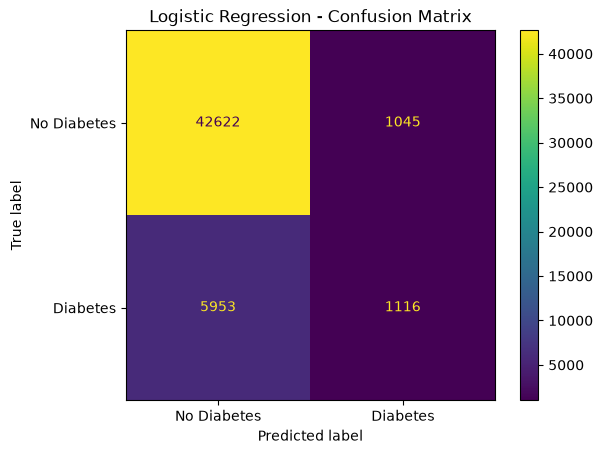

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Confusion matrix

The confusion matrix shows the number of correct and incorrect predictions
for both classes.

- A **false positive** occurs when the model predicts diabetes (class 1)
  for a person who actually belongs to class 0.
- A **false negative** occurs when the model predicts no diabetes (class 0)
  for a person who actually belongs to class 1.

False negatives are particularly important to consider in this problem
because they represent people with diabetes who are not identified as such
by the model.

### Interpretation

The model correctly classified most of the non-diabetes cases, but performed
considerably worse at identifying diabetes cases. There were 5953 false
negatives compared with only 1116 true positives. This results in a low
recall for class 1, meaning that many of the actual diabetes cases were not
identified by the model.

This also demonstrates why accuracy alone is not sufficient for evaluating
the model. Because class 0 is much more common in the dataset, the model can
achieve relatively high accuracy while still failing to identify many of the
diabetes cases.

In [12]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

results

,Metric,Score
0,Accuracy,0.862070
1,Precision,0.516428
2,Recall,0.157872
3,F1 Score,0.241820


### Evaluation metrics

Accuracy measures the proportion of all predictions that were correct.
Precision measures how often a prediction of diabetes was correct.
Recall measures how many of the actual diabetes cases were correctly
identified. The F1 score combines precision and recall into a single
measure.

The model should not be evaluated using accuracy alone, since the class
distribution and the types of classification errors are also important.